In [1]:
import torch
from botorch.models import SingleTaskGP
from botorch.models.transforms import Normalize, Standardize
from botorch.acquisition.multi_objective.logei import qLogExpectedHypervolumeImprovement
from botorch.optim import optimize_acqf
from botorch.utils.multi_objective.box_decompositions.non_dominated import FastNondominatedPartitioning
from botorch.utils.multi_objective.pareto import is_non_dominated
from gpytorch.mlls import ExactMarginalLogLikelihood
from botorch.fit import fit_gpytorch_mll

from collections.abc import Callable

import matplotlib.pyplot as plt

/Users/colin/Library/CloudStorage/OneDrive-UniversityofCambridge/II/Dissertation/MOBO_cloud/.venv/lib/python3.13/site-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


In [2]:
def f_objective(x: torch.Tensor) -> torch.Tensor:
    """
    Blackbox 2D objective function
    """
    f1 = torch.sin(3.0 * torch.pi * x) - 0.4 * x
    f2 = torch.cos(2.0 * torch.pi * (x - 0.5)) + 0.3 * x
    return torch.cat([f1, f2], dim=-1)

In [3]:
def mobo_loop(
    train_x: torch.Tensor,
    train_y: torch.Tensor,
    bounds: torch.Tensor,
    ref_point: torch.Tensor,
    objective: Callable[[torch.Tensor], torch.Tensor],
    runs=10
) -> tuple[torch.Tensor, torch.Tensor]:
    """
    Run MOBO loop, returning new x and y with additional samples
    """
    d = train_x.shape[-1]
    m = train_y.shape[-1]

    for _ in range(runs):
        model = SingleTaskGP(
            train_x,
            train_y,
            input_transform=Normalize(d=d),
            outcome_transform=Standardize(m=m)
        )
        mll = ExactMarginalLogLikelihood(model.likelihood, model)
        fit_gpytorch_mll(mll)

        partitioning = FastNondominatedPartitioning(ref_point=ref_point, Y=train_y)

        acq_func = qLogExpectedHypervolumeImprovement(
            model=model,
            ref_point=ref_point,
            partitioning=partitioning
        )

        candidates, _ = optimize_acqf(
            acq_function=acq_func,
            bounds=bounds,
            q=1,
            num_restarts=5,
            raw_samples=100
        )

        new_y = objective(candidates)
        train_x = torch.cat([train_x, candidates])
        train_y = torch.cat([train_y, new_y])
    
    return (train_x, train_y)

In [4]:
def visualise_pareto(train_x: torch.Tensor, train_y: torch.Tensor, ref_point: torch.Tensor):
    pareto_mask = is_non_dominated(train_y)

    pareto_x = train_x[pareto_mask]
    pareto_y = train_y[pareto_mask]
    dominated_x = train_x[~pareto_mask]
    dominated_y = train_y[~pareto_mask]

    # Sort Pareto points by first objective to plot an ordered frontier
    sorted_indices = torch.argsort(pareto_y[:, 0])
    pareto_x_sorted = pareto_x[sorted_indices]
    pareto_y_sorted = pareto_y[sorted_indices]

    print("\n--- MOBO Finished ---")
    print(f"Total Evaluations: {len(train_x)}")
    print(f"Found {len(pareto_y_sorted)} Pareto-optimal points:")
    for i in range(len(pareto_y_sorted)):
        print(
            f"  x = {pareto_x_sorted[i, 0].item():.4f} --> "
            f"f1 = {pareto_y_sorted[i, 0].item():.3f}, f2 = {pareto_y_sorted[i, 1].item():.3f}"
        )

    # Visualizing trade-off & parameter Space
    _, ax = plt.subplots(1, 1, figsize=(6, 4))

    # Objective space showing Pareto frontier
    ax.scatter(
        dominated_y[:, 0].numpy(),
        dominated_y[:, 1].numpy(),
        color="gray",
        alpha=0.6,
        label="Dominated Points",
    )
    ax.scatter(
        pareto_y_sorted[:, 0].numpy(),
        pareto_y_sorted[:, 1].numpy(),
        color="crimson",
        s=80,
        edgecolors="k",
        zorder=5,
        label="Pareto Front (Non-dominated)",
    )
    ax.plot(
        pareto_y_sorted[:, 0].numpy(),
        pareto_y_sorted[:, 1].numpy(),
        "r--",
        alpha=0.7,
        label="Empirical Front",
    )
    ax.step(
        pareto_y_sorted[:, 0].numpy(),
        pareto_y_sorted[:, 1].numpy(),
        where="post",
        color="crimson",
        alpha=0.3,
    )
    ax.scatter(
        [ref_point[0].item()],
        [ref_point[1].item()],
        color="black",
        marker="x",
        s=60,
        label="Reference Point",
    )

    ax.set_title("Objective Space: Constructed Pareto Frontier", fontweight="bold")
    ax.set_xlabel("Objective 1 ($f_1$) [Maximise]", fontsize=11)
    ax.set_ylabel("Objective 2 ($f_2$) [Maximise]", fontsize=11)
    ax.grid(True, linestyle=":", alpha=0.6)
    ax.legend()

    plt.tight_layout()
    plt.show()


--- MOBO Finished ---
Total Evaluations: 15
Found 11 Pareto-optimal points:
  x = 10.0000 --> f1 = -4.000, f2 = 2.000
  x = 5.2617 --> f1 = -2.730, f2 = 1.652
  x = 0.5258 --> f1 = -1.181, f2 = 1.145
  x = 0.5815 --> f1 = -0.952, f2 = 1.046
  x = 0.4008 --> f1 = -0.754, f2 = 0.932
  x = 0.6291 --> f1 = -0.598, f2 = 0.877
  x = 0.3365 --> f1 = -0.165, f2 = 0.618
  x = 0.3318 --> f1 = -0.119, f2 = 0.591
  x = 0.3097 --> f1 = 0.097, f2 = 0.460
  x = 0.3042 --> f1 = 0.149, f2 = 0.425
  x = 0.8265 --> f1 = 0.667, f2 = -0.214


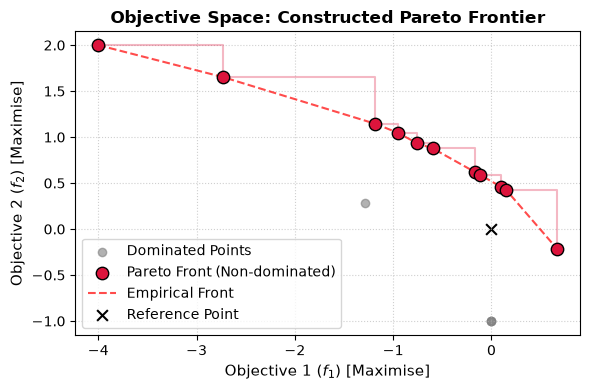

In [5]:
tkwargs = {"dtype": torch.double, "device": torch.device("cpu")}
torch.manual_seed(42)

bounds = torch.tensor([[0.0], [10.0]], **tkwargs)
ref_point = torch.tensor([0.0, 0.0], **tkwargs)

n_init = 5
train_x = bounds[0] + (bounds[1] - bounds[0]) * torch.rand(n_init, 1, dtype=torch.double)
train_y = f_objective(train_x)

RUNS = 10
train_x, train_y = mobo_loop(train_x, train_y, bounds, ref_point, f_objective)
visualise_pareto(train_x, train_y, ref_point)

In [6]:
from botorch.test_functions.multi_objective import BraninCurrin
from botorch.utils.sampling import draw_sobol_samples

In [7]:
# Standard MOBO benchmark problem
problem = BraninCurrin(negate=True).to(**tkwargs)

NOISE_SE = torch.tensor([15.19, 0.63], **tkwargs)

In [8]:
def generate_initial_data(n=5):
    train_x = draw_sobol_samples(bounds=problem.bounds, n=n, q=1).squeeze(1)
    train_obj_true = problem(train_x)
    train_obj = train_obj_true + torch.randn_like(train_obj_true) * NOISE_SE
    return train_x, train_obj, train_obj_true


--- MOBO Finished ---
Total Evaluations: 35
Found 19 Pareto-optimal points:
  x = 0.0000 --> f1 = -17.508, f2 = -1.180
  x = 0.0041 --> f1 = -16.203, f2 = -1.347
  x = 0.0084 --> f1 = -14.883, f2 = -1.523
  x = 0.0145 --> f1 = -13.135, f2 = -1.769
  x = 0.0209 --> f1 = -11.424, f2 = -2.028
  x = 0.0265 --> f1 = -10.067, f2 = -2.248
  x = 0.0324 --> f1 = -8.767, f2 = -2.475
  x = 0.0380 --> f1 = -7.674, f2 = -2.681
  x = 0.0434 --> f1 = -6.724, f2 = -2.878
  x = 0.0530 --> f1 = -5.339, f2 = -3.231
  x = 0.0619 --> f1 = -4.260, f2 = -3.556
  x = 0.0762 --> f1 = -3.634, f2 = -3.917
  x = 0.0810 --> f1 = -2.551, f2 = -4.181
  x = 0.0860 --> f1 = -2.023, f2 = -4.389
  x = 0.0946 --> f1 = -1.807, f2 = -4.588
  x = 0.0977 --> f1 = -1.260, f2 = -4.777
  x = 0.1054 --> f1 = -0.958, f2 = -5.002
  x = 0.1155 --> f1 = -0.615, f2 = -5.324
  x = 0.1227 --> f1 = -0.552, f2 = -5.523


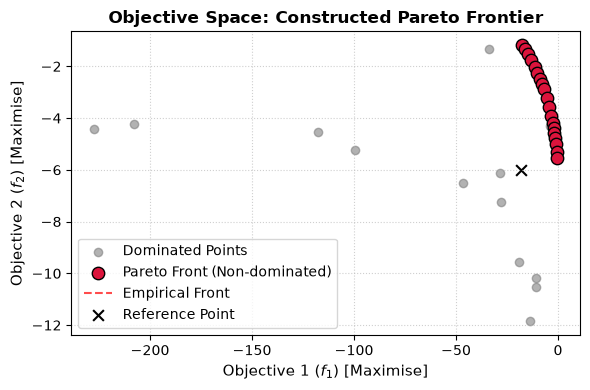

In [9]:
train_x, _, train_y = generate_initial_data()
train_x, train_y = mobo_loop(train_x, train_y, problem.bounds, problem.ref_point, problem, 30)
visualise_pareto(train_x, train_y, problem.ref_point)